# Chapitre 14 - Cours 3 : cartes auto-organisatrices, ACP et ses extensions, ACI, MDS

Ce notebook couvre les sections 14.4 à 14.8 du livre : des méthodes qui cherchent une
**structure de petite dimension** (une variété, des sources cachées, une carte du plan)
rendant compte de données de grande dimension.

1. cartes auto-organisatrices de Kohonen (SOM, figures 14.15 à 14.18) ;
2. analyse en composantes principales (figures 14.20 à 14.24) ;
3. analyse de Procrustes et formes moyennes (figures 14.25, 14.26) ;
4. courbes principales (figure 14.27) ;
5. clustering spectral et ACP à noyau (figures 14.29, 14.30) ;
6. ACP parcimonieuse et factorisation en matrices positives (présentation) ;
7. analyse factorielle et analyse en composantes indépendantes (figures 14.37, 14.38) ;
8. positionnement multidimensionnel (MDS, figure 14.43).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## 1. Cartes auto-organisatrices (section 14.4)

### 1.1 Principe

Une carte auto-organisatrice (*self-organizing map*, SOM) est une version **contrainte** des
K-means : les $K = q_1 q_2$ prototypes $m_j \in \mathbb{R}^p$ sont indexés par les nœuds
$\ell_j \in \{1..q_1\} \times \{1..q_2\}$ d'une grille du plan, et l'on veut que des nœuds voisins
sur la grille aient des prototypes proches dans $\mathbb{R}^p$. Image : des « boutons » cousus
régulièrement sur un tissu (initialement le plan des deux premières composantes principales),
que l'on déforme pour approcher au mieux les données.

**Algorithme (version en ligne).** Les observations sont traitées une par une. Pour $x_i$ :

1. on trouve le prototype le plus proche $m_j$ (distance euclidienne dans $\mathbb{R}^p$) ;
2. on déplace vers $x_i$ ce prototype **et ses voisins sur la grille** :
   $$m_k \leftarrow m_k + \alpha\,(x_i - m_k) \quad \text{pour tout } k \text{ tel que }
   \|\ell_j - \ell_k\| < r \qquad (14.46).$$

Le taux d'apprentissage $\alpha$ décroît (par exemple de 1 à 0) et le rayon $r$ de $R$ à 1 au fil
des itérations. Une variante pondère la mise à jour par $h(\|\ell_j - \ell_k\|)$, décroissante
de la distance sur la grille (14.47).

> **Intuition.** La distance qui définit le voisinage se mesure **sur la grille**, pas dans
> $\mathbb{R}^p$ : c'est ce qui force la carte à rester « lisse ». Si $r$ est si petit qu'un
> voisinage ne contient que le prototype gagnant, la SOM devient une version en ligne des
> K-means.

### 1.2 Données sur une demi-sphère (figure 14.15)

On simule 90 points en dimension 3, en trois groupes de 30 situés près de $(0,0,1)$ (groupe
rouge, le plus resserré en angle), $(1,0,0)$ et $(0,1,0)$, avec un bruit gaussien
d'écart-type 0,6 sur chaque coordonnée (détails dans l'exercice 14.5).

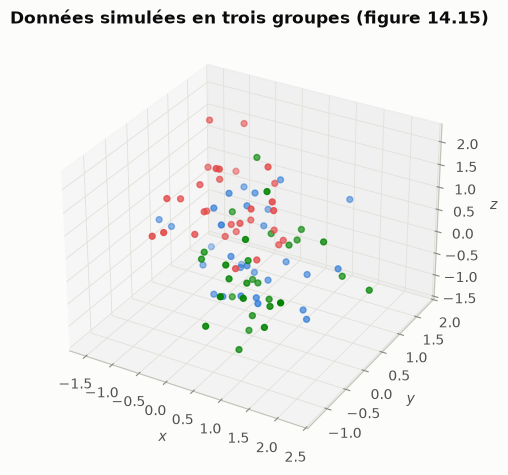

In [2]:
Xs, ys = ns.donnees_demi_sphere(rng=np.random.RandomState(0))
coul_s = np.array([COLORS[7], COLORS[5], COLORS[0]])[ys]
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*Xs.T, c=coul_s, s=18)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$z$")
ax.set_title("Données simulées en trois groupes (figure 14.15)")
plt.show()

On ajuste une grille $5 \times 5$ avec un rayon initial $R = 2$ (environ un tiers des prototypes
dans chaque voisinage), 40 passages sur les 90 observations (3600 itérations), $\alpha$ et $r$
décroissant linéairement.

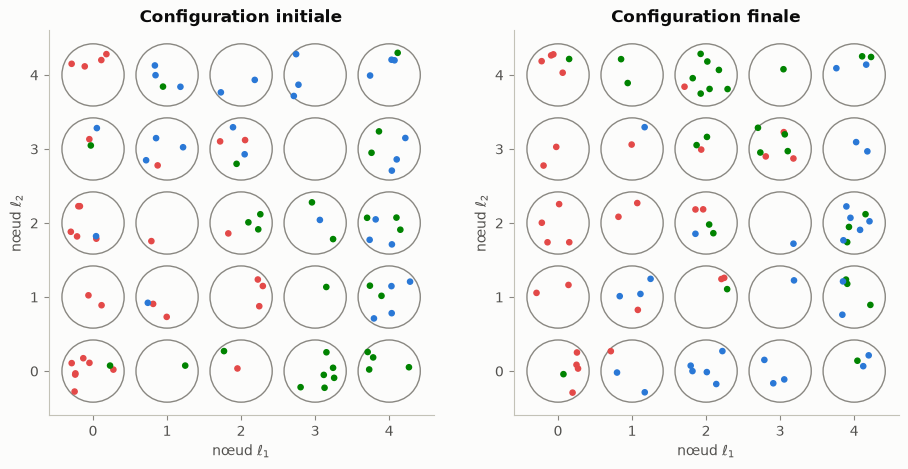

In [3]:
som0 = ns.init_som_acp(Xs, 5, 5)
res_som = ns.som(Xs, 5, 5, n_iter=3600, R=2.0, rng=np.random.RandomState(0), suivi=45)
lab_init = ns.distances_carrees(Xs, som0).argmin(1)


def dessiner_carte(ax, labels, grille, titre, rng):
    for (a, b) in grille:
        ax.add_patch(plt.Circle((a, b), 0.42, fill=False, color=GRAY))
    jit = rng.uniform(-0.3, 0.3, size=(len(labels), 2))
    pos = grille[labels] + jit
    ax.scatter(*pos.T, c=coul_s, s=14)
    ax.set_xlim(-0.6, 4.6)
    ax.set_ylim(-0.6, 4.6)
    ax.set_aspect("equal")
    ax.set_title(titre)
    ax.set_xlabel("nœud $\\ell_1$")
    ax.set_ylabel("nœud $\\ell_2$")
    ax.grid(False)


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
r_jit = np.random.RandomState(1)
dessiner_carte(axes[0], lab_init, res_som["grille"], "Configuration initiale", r_jit)
dessiner_carte(axes[1], res_som["labels"], res_som["grille"], "Configuration finale", r_jit)
plt.show()

Chaque cercle est un prototype ; les points qui s'y projettent sont dessinés au hasard dans le
cercle (figure 14.16). Au départ (plan principal), les groupes se mélangent ; à la fin, ils
occupent des régions distinctes de la carte.

Représentons la carte ajustée dans $\mathbb{R}^3$ : les prototypes et les arêtes de la grille
(figure 14.17).

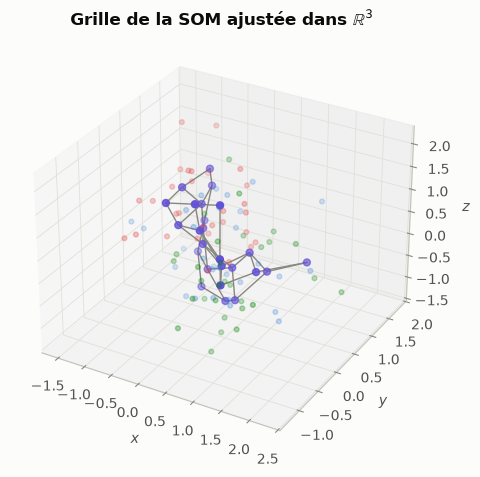

In [4]:
M = res_som["prototypes"].reshape(5, 5, 3)
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*Xs.T, c=coul_s, s=12, alpha=0.6)
for a in range(5):
    ax.plot(*M[a, :, :].T, color=GRAY, lw=1)
    ax.plot(*M[:, a, :].T, color=GRAY, lw=1)
ax.scatter(*res_som["prototypes"].T, color=COLORS[6], s=25)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$z$")
ax.set_title("Grille de la SOM ajustée dans $\\mathbb{R}^3$")
plt.show()

### 1.3 Erreur de reconstruction (figure 14.18)

Pour juger si la contrainte de la carte est raisonnable, on compare l'erreur de
reconstruction $\sum_i \|x_i - m_{j(i)}\|^2$ ($m_{j(i)}$ : prototype le plus proche) à celle des
K-means avec 25 centres, nécessairement plus petite. On ajoute la **version batch** de la SOM
(éq. (14.48)) : chaque prototype devient la moyenne des observations affectées à ses voisins
sur la grille ; quand le voisinage se réduit au seul gagnant, c'est exactement une itération des
K-means.

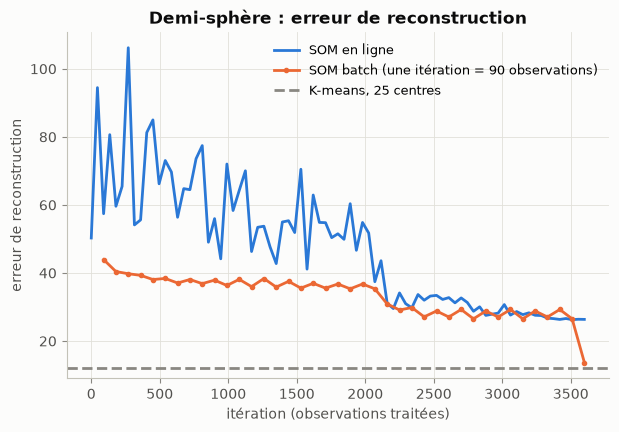

In [5]:
km25 = ns.kmeans(Xs, 25, n_init=10, rng=np.random.RandomState(0))
res_batch = ns.som_batch(Xs, 5, 5, n_iter=40, R=2.0, r_final=1.0)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(res_som["historique"][:, 0], res_som["historique"][:, 1], color=BLUE,
        label="SOM en ligne")
ax.plot(np.arange(1, 41) * 90, res_batch["historique"], "o-", ms=3, color=ORANGE,
        label="SOM batch (une itération = 90 observations)")
ax.axhline(km25[2], color=GRAY, ls="--", label="K-means, 25 centres")
ax.set_xlabel("itération (observations traitées)")
ax.set_ylabel("erreur de reconstruction")
ax.set_title("Demi-sphère : erreur de reconstruction")
ax.legend()
plt.show()

In [6]:
print("Erreur finale : SOM en ligne %.1f, SOM batch %.1f, K-means %.1f"
      % (res_som["erreur"], res_batch["erreur"], km25[2]))

Erreur finale : SOM en ligne 26.4, SOM batch 13.6, K-means 12.1


La SOM fait fortement baisser l'erreur. Avec le schéma en ligne (α décroissant linéairement
jusqu'à 0), les prototypes restent toutefois éloignés des moyennes de leurs cellules ; la
version batch, dont le voisinage final se réduit au gagnant, atteint presque le niveau des
K-means, signe que la contrainte bidimensionnelle est raisonnable ici.

> **À retenir.** Une SOM est un K-means dont les centres sont attachés aux nœuds d'une grille et
> mis à jour avec leurs voisins. Elle fournit une **carte** bidimensionnelle des données, mais
> les distances sur la carte ne reflètent pas les distances dans $\mathbb{R}^p$.

## 2. Composantes principales (section 14.5.1)

### 2.1 Meilleure approximation linéaire de rang $q$

On cherche le sous-espace affine de dimension $q$ qui approche au mieux les données :
$f(\lambda) = \mu + \mathbf{V}_q \lambda$ (14.49), où $\mathbf{V}_q$ est une matrice $p \times q$ à
colonnes orthonormées et $\lambda \in \mathbb{R}^q$. On minimise

$$\min_{\mu, \{\lambda_i\}, \mathbf{V}_q} \sum_{i=1}^N \|x_i - \mu - \mathbf{V}_q \lambda_i\|^2
\qquad (14.50).$$

On montre (exercice 14.7) que $\hat\mu = \bar x$ et $\hat\lambda_i = \mathbf{V}_q^T(x_i - \bar x)$
(14.51)-(14.52), puis qu'il reste à minimiser $\sum_i \|(x_i - \bar x) - \mathbf{V}_q\mathbf{V}_q^T
(x_i - \bar x)\|^2$ (14.53) : $\mathbf{V}_q\mathbf{V}_q^T$ est le projecteur orthogonal sur le
sous-espace. Avec la décomposition en valeurs singulières de la matrice centrée
$\mathbf{X} = \mathbf{U}\mathbf{D}\mathbf{V}^T$ (14.54), la solution est formée des $q$ premières
colonnes de $\mathbf{V}$, et les $\hat\lambda_i$ sont les lignes de $\mathbf{U}_q\mathbf{D}_q$, les
**composantes principales**.

### 2.2 Plan principal de la demi-sphère (figure 14.21)

In [ ]:
pca_s = ns.acp(Xs, 2)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(*pca_s["scores"].T, c=coul_s, s=18)
ax.set_xlabel("première composante principale")
ax.set_ylabel("deuxième composante principale")
ax.set_title("Projection de la demi-sphère sur le plan principal")
plt.show()